# 07 · Validation on real data: IBM Telco customer churn

The main pipeline runs on simulated data, so its accuracy partly reflects how the simulation was
built. This notebook checks that the **same modelling approach** - class-weighted XGBoost with
Platt calibration, compared against logistic regression and a simple rule, judged on PR-AUC,
capture and calibration, explained with SHAP - holds up on a public, real-world churn dataset.

**Dataset:** IBM *Telco Customer Churn* sample (7,043 customers, 26.5% churn), from
[IBM/telco-customer-churn-on-icp4d](https://github.com/IBM/telco-customer-churn-on-icp4d).
It is a cross-sectional snapshot (no monthly history), so the split is stratified random rather
than temporal, and the rule baseline is "month-to-month contract". Pure pandas - no Spark needed.

In [1]:
%pip install -q -r ../requirements.txt

In [2]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from revenue_pipeline import config, modeling, charts

charts.apply_style()
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
cache = config.REPO_ROOT / "data" / "external" / "Telco-Customer-Churn.csv"
if not cache.exists():
    cache.parent.mkdir(parents=True, exist_ok=True)
    pd.read_csv(URL).to_csv(cache, index=False)
raw = pd.read_csv(cache)
print(raw.shape, f"churn rate {(raw['Churn'] == 'Yes').mean():.1%}")

(7043, 21) churn rate 26.5%


In [3]:
df = raw.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
y = (df.pop("Churn") == "Yes").astype(int)
arr = df["MonthlyCharges"] * 12
X = pd.get_dummies(df.drop(columns=["customerID"]), drop_first=True, dtype=float)

idx = np.arange(len(X))
train_idx, rest = train_test_split(idx, test_size=0.4, stratify=y, random_state=config.SEED)
calib_idx, test_idx = train_test_split(rest, test_size=0.5, stratify=y.iloc[rest], random_state=config.SEED)
part = lambda o, i: o.iloc[i]
print(f"train {len(train_idx):,} | calibration {len(calib_idx):,} | test {len(test_idx):,}")

train 4,225 | calibration 1,409 | test 1,409


In [4]:
y_tr = part(y, train_idx)
booster = xgb.XGBClassifier(scale_pos_weight=(y_tr == 0).sum() / (y_tr == 1).sum(), **config.XGB_PARAMS)
booster.fit(part(X, train_idx), y_tr)
platt = modeling.PlattCalibrator().fit(booster.predict_proba(part(X, calib_idx))[:, 1], part(y, calib_idx))
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(
    part(X, np.r_[train_idx, calib_idx]), part(y, np.r_[train_idx, calib_idx]))

X_te, y_te, arr_te = part(X, test_idx), part(y, test_idx), part(arr, test_idx)
raw_scores = booster.predict_proba(X_te)[:, 1]
scores = {
    "Rule: month-to-month contract": (1 - X_te["Contract_One year"] - X_te["Contract_Two year"]).to_numpy(),
    "Logistic regression": logit.predict_proba(X_te)[:, 1],
    "XGBoost (raw, class-weighted)": raw_scores,
    "XGBoost + Platt calibration": platt.predict(raw_scores),
}
metrics = pd.DataFrame({k: modeling.evaluate(y_te, p, arr_te, top_frac=0.10) for k, p in scores.items()}).T
metrics.loc["Rule: month-to-month contract", ["brier", "log_loss", "predicted_churners"]] = np.nan
print(metrics.round(4).to_string())

                               roc_auc  pr_auc   brier  log_loss  precision_top10  recall_top10  churned_arr_captured_top10  predicted_churners  actual_churners
Rule: month-to-month contract    0.710  0.3926     NaN       NaN           0.4571        0.1711                      0.1585                 NaN            374.0
Logistic regression              0.832  0.6187  0.1417    0.4323           0.7071        0.2647                      0.2829            378.2780            374.0
XGBoost (raw, class-weighted)    0.837  0.6424  0.1685    0.5006           0.7000        0.2620                      0.2842            592.1329            374.0
XGBoost + Platt calibration      0.837  0.6424  0.1398    0.4277           0.7000        0.2620                      0.2842            372.8574            374.0


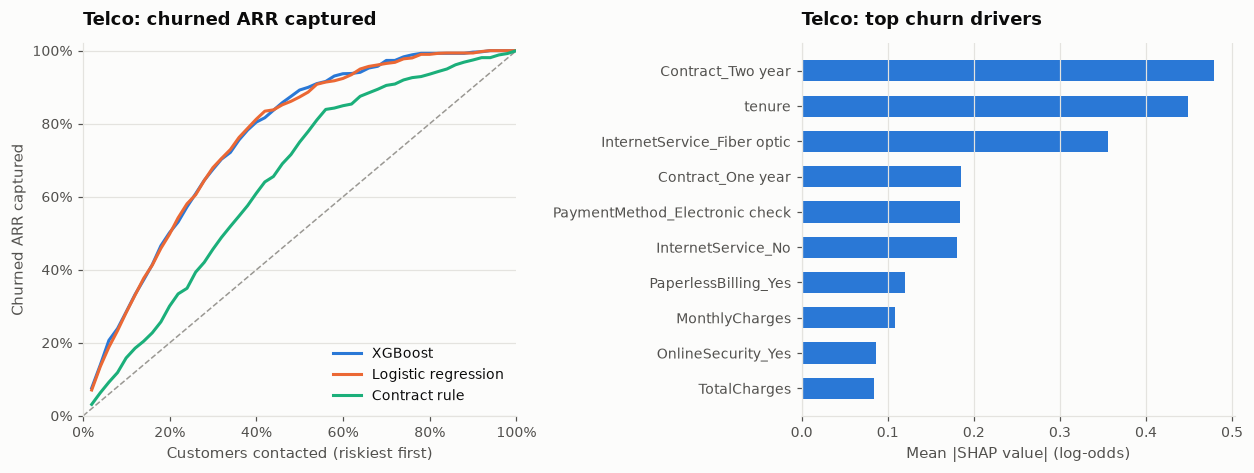

In [5]:
import shap

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
ax = axes[0]
ax.plot([0, 1], [0, 1], color=charts.REFERENCE, lw=1, ls="--")
for (key, label), color in zip([("XGBoost + Platt calibration", "XGBoost"), ("Logistic regression", "Logistic regression"),
                                ("Rule: month-to-month contract", "Contract rule")], charts.SERIES):
    c = modeling.capture_curve(y_te, scores[key], arr_te)
    ax.plot(c["pct_targeted"], c["churned_arr_captured"], color=color, label=label)
charts.percent(ax, "x"); charts.percent(ax, "y")
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="Customers contacted (riskiest first)", ylabel="Churned ARR captured")
ax.set_title("Telco: churned ARR captured")
ax.legend(loc="lower right")

values = shap.TreeExplainer(booster).shap_values(X_te)
imp = pd.Series(np.abs(values).mean(axis=0), index=X.columns).sort_values().tail(10)
ax = axes[1]
ax.barh(imp.index, imp.values, color=charts.SERIES[0], height=0.6)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("Mean |SHAP value| (log-odds)")
ax.set_title("Telco: top churn drivers")
fig.tight_layout()
charts.save(fig, "telco_validation.png"); plt.show()

In [6]:
p = scores["XGBoost + Platt calibration"]
print(f"Test set: {y_te.sum()} actual churners vs {p.sum():.0f} predicted (calibrated)")
print(f"Annualised revenue at risk in test set: ${(p * arr_te).sum():,.0f} "
      f"(actual churned ARR ${(y_te * arr_te).sum():,.0f})")
out = metrics.reset_index().rename(columns={"index": "model"})
config.GOLD_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
out.to_csv(config.GOLD_EXPORT_DIR / "telco_model_metrics.csv", index=False)

Test set: 374 actual churners vs 373 predicted (calibrated)
Annualised revenue at risk in test set: $333,791 (actual churned ARR $337,971)
